# K-Nearest Neighbours (KNN) from Scratch
### Handwritten digit recognition with NumPy

This notebook implements the **k-nearest neighbours classifier from scratch** (NumPy only) and uses it to recognise
handwritten digits from the scikit-learn [digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
scikit-learn is used **only** to load the data and split it into train and test sets. The distance functions, the KNN class,
the metrics and the confusion matrix are all written by hand.

**Result:** 98.3% test accuracy (354 of 360 digits correct) with k = 5.

**Contents**
1. Imports
2. Load the dataset
3. DataFrame view
4. Train/test split
5. Distance functions
6. The KNN class
7. Fit and evaluate
8. Confusion matrix and per-class metrics
9. Effect of k
10. Results, limitations and next steps

---

## How KNN works

KNN is a **lazy learner**: there is no training step, it just stores the training data. To classify a new point $q$:

1. Compute the distance from $q$ to every training point.
2. Pick the $k$ closest training points (the *neighbours*).
3. Predict the **majority class** among those neighbours.

**Images as vectors.** Each digit is an 8×8 grayscale image with pixel values from 0 to 16. Flattening it gives a vector of 64 numbers,
so every image is a point in 64-dimensional space and "similar-looking digits" means "nearby points".

## 1. Imports

In [99]:
# NumPy does all the maths, matplotlib draws the plots, pandas is used only to inspect the data,
# and scikit-learn is used just to load the dataset and split it.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

## 2. Load the dataset

The dataset has **1,797 images** of handwritten digits (classes `0` to `9`), each stored as 64 pixel values.
`digits.data` has shape `(1797, 64)`.

In [100]:
# Load the digits dataset: 1,797 images, each flattened to 64 pixel values.
digits = load_digits()
print(digits.data.shape)


(1797, 64)


Display one sample image (the digit at index 2) to see what the model is working with.

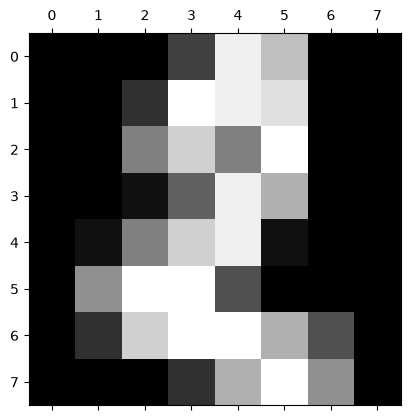

In [101]:
# Show one digit image (an 8x8 grid of pixel intensities).
plt.matshow(digits.images[2], cmap="gray")
plt.show()

## 3. DataFrame view

Load the same data as a pandas DataFrame (one column per pixel, `pixel_row_col`) and a target Series with the digit labels.
This is only for inspection; the model itself works on NumPy arrays.

In [102]:
# Load the same data as a DataFrame (features) and a Series (labels 0-9).
df, target = load_digits(return_X_y= True, as_frame= True)

In [103]:
# Preview the feature table: one row per image, one column per pixel.
df

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0


In [104]:
# The labels: the digit shown in each image.
target

0       0
1       1
2       2
3       3
4       4
       ..
1792    9
1793    0
1794    8
1795    9
1796    8
Name: target, Length: 1797, dtype: int64

In [105]:
# Summary statistics of the pixel columns.
# (Add parentheses, df.describe(), to print the table instead of the method object.)
df.describe

<bound method NDFrame.describe of       pixel_0_0  pixel_0_1  pixel_0_2  pixel_0_3  pixel_0_4  pixel_0_5  \
0           0.0        0.0        5.0       13.0        9.0        1.0   
1           0.0        0.0        0.0       12.0       13.0        5.0   
2           0.0        0.0        0.0        4.0       15.0       12.0   
3           0.0        0.0        7.0       15.0       13.0        1.0   
4           0.0        0.0        0.0        1.0       11.0        0.0   
...         ...        ...        ...        ...        ...        ...   
1792        0.0        0.0        4.0       10.0       13.0        6.0   
1793        0.0        0.0        6.0       16.0       13.0       11.0   
1794        0.0        0.0        1.0       11.0       15.0        1.0   
1795        0.0        0.0        2.0       10.0        7.0        0.0   
1796        0.0        0.0       10.0       14.0        8.0        1.0   

      pixel_0_6  pixel_0_7  pixel_1_0  pixel_1_1  ...  pixel_6_6  pixel_6_7  

## 4. Train/test split

We hold out **20%** of the data (360 images) as a test set used only for evaluation, leaving 1,437 images for the stored training set.

- `stratify=target` keeps the proportion of each digit the same in both splits.
- `random_state=42` makes the split reproducible.

In [106]:
# 80/20 stratified split. Stratifying keeps the share of each digit
# the same in the train and test sets.
x_train, x_test, y_train, y_test = train_test_split(
    df.values, target.values,
    random_state= 42,
    stratify= target,
    test_size= 0.2
)

In [107]:
# Number of test images and features: (360, 64).
x_test.shape

(360, 64)

In [108]:
# Number of training images and features: (1437, 64).
x_train.shape

(1437, 64)

In [109]:
# Raw (unscaled) training pixels. Scaling is skipped on purpose, see the note above.
x_train

array([[ 0.,  0., 11., ...,  2.,  0.,  0.],
       [ 0.,  0.,  2., ...,  1.,  0.,  0.],
       [ 0.,  1., 15., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  1., ...,  3.,  0.,  0.],
       [ 0.,  0.,  4., ...,  0.,  0.,  0.],
       [ 0.,  0.,  3., ..., 16., 16.,  3.]], shape=(1437, 64))

In [110]:
# True labels of the test images.
y_test

array([5, 2, 8, 1, 7, 2, 6, 2, 6, 5, 0, 5, 9, 3, 4, 4, 2, 4, 9, 9, 6, 3,
       8, 1, 2, 5, 6, 0, 3, 4, 6, 7, 2, 6, 6, 6, 6, 5, 0, 9, 1, 7, 9, 6,
       5, 7, 5, 2, 7, 5, 0, 8, 5, 5, 3, 2, 4, 0, 0, 2, 7, 5, 6, 1, 3, 7,
       6, 5, 7, 0, 9, 0, 3, 8, 2, 5, 8, 2, 3, 5, 9, 3, 2, 7, 9, 6, 8, 1,
       0, 1, 2, 9, 4, 9, 1, 2, 7, 8, 4, 2, 6, 9, 3, 7, 3, 9, 6, 1, 1, 0,
       9, 2, 1, 6, 3, 4, 8, 7, 1, 0, 0, 4, 6, 5, 8, 2, 8, 8, 3, 0, 0, 8,
       6, 4, 3, 9, 3, 3, 3, 3, 0, 7, 0, 0, 1, 9, 5, 8, 1, 5, 0, 6, 6, 6,
       6, 1, 7, 7, 6, 7, 7, 8, 7, 3, 6, 5, 9, 0, 3, 8, 0, 9, 8, 1, 9, 5,
       9, 5, 8, 9, 9, 7, 9, 1, 9, 5, 4, 7, 3, 0, 4, 9, 7, 7, 5, 6, 5, 8,
       3, 4, 5, 4, 9, 2, 5, 5, 2, 1, 3, 8, 8, 9, 3, 6, 1, 0, 1, 4, 0, 5,
       5, 6, 6, 7, 4, 3, 8, 4, 1, 0, 7, 9, 2, 8, 4, 8, 4, 2, 4, 0, 0, 0,
       2, 6, 7, 0, 4, 5, 2, 2, 9, 0, 4, 6, 8, 2, 3, 9, 2, 3, 0, 6, 8, 7,
       1, 4, 4, 1, 1, 6, 3, 8, 1, 2, 5, 7, 8, 3, 2, 0, 3, 4, 1, 9, 9, 9,
       6, 3, 7, 1, 6, 9, 4, 7, 1, 8, 1, 3, 0, 5, 3,

### A note on feature scaling

KNN is distance-based, so features usually need to be scaled. Here we **deliberately do not scale**: every feature is a pixel
intensity on the same 0 to 16 range, so no feature dominates the distance.

In a separate check with this same split, standardising each pixel (zero mean, unit variance) actually *lowered* accuracy
from about 98.3% to 96.4% at k = 5. Standardising divides each pixel by its own standard deviation, which inflates rarely-used
border pixels (almost always 0) and lets noise there count as much as the centre of the digit. Scaling is a choice to test, not an automatic step.

## 5. Distance functions

Each function takes the matrix of training points `given_pt` (shape `n × 64`) and one query point `query` (shape `64`),
and returns the distance from the query to **every** training point as a vector of length `n`. NumPy broadcasting avoids a Python loop.

| Metric | Formula |
|---|---|
| Euclidean | $d(x,y)=\sqrt{\sum_j (x_j-y_j)^2}$ |
| Manhattan | $d(x,y)=\sum_j \lvert x_j-y_j\rvert$ |
| Minkowski | $d(x,y)=\left(\sum_j \lvert x_j-y_j\rvert^{p}\right)^{1/p}$ |

Minkowski generalises the other two: $p=1$ gives Manhattan and $p=2$ gives Euclidean. The model below uses Euclidean distance.

In [111]:
# Distance from `query` to every row of `given_pt` (broadcasting, no loop).
# (The name `euclidian` is kept as in the original code.)
def euclidian(given_pt, query):
    dist = np.sqrt(((given_pt - query) ** 2).sum(axis = 1))
    return dist

def manhattan(given_pt, query):
    dist = (abs(given_pt - query)).sum(axis = 1)
    return dist

def minkowski(given_pt, query, p):
    dist = ((np.abs(given_pt - query) ** p).sum(axis = 1)) ** (1/p)
    return dist

## 6. The KNN class

- `fit` stores the training data (there is nothing to learn).
- `get_neighbours` returns the indices of the $k$ training points closest to a query `q`.
- `predict_lable` classifies one query by **majority vote**: `np.bincount` counts the votes for each digit and `argmax` picks the winner.
- `predict` applies this to every row of a test matrix.

In [112]:
# KNN classifier. fit() only stores the data; all the work happens at prediction time.
class KNN:
    def __init__(self, k=5, dist_fn=euclidian):
        self.k = k
        self.dist_fn = dist_fn

    def fit(self, X_train, y_train):
        # KNN just stores the data
        self.X_train = X_train
        self.y_train = y_train
        return self

    def get_neighbours(self, q):
        dist = self.dist_fn(self.X_train, q)
        return np.argsort(dist)[:self.k]

    def predict_lable(self, q):
        idx = self.get_neighbours(q)
        return np.bincount(self.y_train[idx]).argmax()

    def predict(self, X_test):
        return np.array([self.predict_lable(q) for q in X_test])

## 7. Fit and evaluate

Fit the model on the training set with $k=5$ and predict the test set. **Accuracy** is the fraction of correct predictions:

$$\text{accuracy}=\frac{\text{correct predictions}}{\text{total predictions}}=\frac{354}{360}\approx 0.983$$

In [113]:
# Fit on the training set, predict the test set, and report accuracy
# (mean of the True/False matches).
model = KNN(k=5).fit(x_train, y_train)
y_pred = model.predict(x_test)
print(np.mean(y_pred == y_test))

0.9833333333333333


## 8. Confusion matrix and per-class metrics

Accuracy alone does not show *which* digits get confused. With 10 classes we build a **10×10 confusion matrix**:
rows are the actual digit, columns are the predicted digit, and the diagonal holds the correct predictions.

For each digit $c$:

$$\text{precision}_c=\frac{TP_c}{\text{all predicted as } c}\qquad \text{recall}_c=\frac{TP_c}{\text{all actually } c}$$

- **Precision:** when the model says "8", how often is it right?
- **Recall:** of all the real 8s, how many did the model find?

The weakest digits are **8** (precision 0.941, recall 0.914) and **9** (recall 0.944). The model finds almost every other digit.

0 precision 1.000  recall 1.000
1 precision 0.947  recall 1.000
2 precision 1.000  recall 1.000
3 precision 1.000  recall 1.000
4 precision 0.973  recall 1.000
5 precision 1.000  recall 1.000
6 precision 1.000  recall 0.972
7 precision 0.973  recall 1.000
8 precision 0.941  recall 0.914
9 precision 1.000  recall 0.944


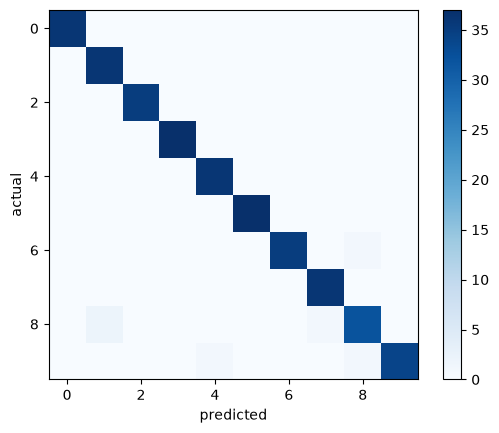

In [115]:
# 10x10 confusion matrix: rows = actual digit, columns = predicted digit.
# Precision uses column sums, recall uses row sums.
n = 10
cm = np.zeros((n, n), dtype=int)
np.add.at(cm, (y_test, y_pred), 1)        # rows = actual, cols = predicted

tp = np.diag(cm)
precision = tp / cm.sum(axis=0)           # per predicted class
recall    = tp / cm.sum(axis=1)           # per actual class
for d in range(n):
    print(d, f"precision {precision[d]:.3f}  recall {recall[d]:.3f}")

plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xlabel("predicted"); plt.ylabel("actual"); plt.show()

## 9. Effect of k

Run the classifier for every $k$ from 1 to 99 and plot accuracy against $k$.

- **Small k** (1 to 3) gives about 98.6%: with clean, well-separated classes the single closest examples are very informative.
- **Large k** averages over more and more distant points, so the vote is increasingly dominated by whichever classes are common nearby, and accuracy falls steadily (below 96% from k = 24, about 91% at k = 99).

**Caveat:** this sweep is evaluated on the **test set**, so it shows the trend but should not be used to *pick* k and then report that score,
since that would make the test accuracy optimistic. A proper choice of k uses cross-validation on the training data only.

In [116]:
# Sweep k = 1..99 and record test accuracy for each.
# Note: evaluated on the test set, so this shows the trend rather than a tuned score.
arr = []

for i in range(1, 100, 1):
    model_ = KNN(k=i).fit(x_train, y_train)
    y_pred = model_.predict(x_test)
    arr.append(np.mean(y_pred == y_test))

In [117]:
# Accuracy for every k.
arr

[np.float64(0.9861111111111112),
 np.float64(0.9861111111111112),
 np.float64(0.9861111111111112),
 np.float64(0.9833333333333333),
 np.float64(0.9833333333333333),
 np.float64(0.9805555555555555),
 np.float64(0.9833333333333333),
 np.float64(0.9777777777777777),
 np.float64(0.9805555555555555),
 np.float64(0.9777777777777777),
 np.float64(0.9777777777777777),
 np.float64(0.975),
 np.float64(0.975),
 np.float64(0.9777777777777777),
 np.float64(0.975),
 np.float64(0.9777777777777777),
 np.float64(0.9722222222222222),
 np.float64(0.9694444444444444),
 np.float64(0.9666666666666667),
 np.float64(0.9666666666666667),
 np.float64(0.9638888888888889),
 np.float64(0.9611111111111111),
 np.float64(0.9638888888888889),
 np.float64(0.9583333333333334),
 np.float64(0.9611111111111111),
 np.float64(0.9611111111111111),
 np.float64(0.9611111111111111),
 np.float64(0.9611111111111111),
 np.float64(0.9611111111111111),
 np.float64(0.9611111111111111),
 np.float64(0.9611111111111111),
 np.float64(0.96

In [118]:
# Accuracies as a NumPy array (the y-axis of the plot).
y = np.array(arr)

In [119]:
# Display the array.
y

array([0.98611111, 0.98611111, 0.98611111, 0.98333333, 0.98333333,
       0.98055556, 0.98333333, 0.97777778, 0.98055556, 0.97777778,
       0.97777778, 0.975     , 0.975     , 0.97777778, 0.975     ,
       0.97777778, 0.97222222, 0.96944444, 0.96666667, 0.96666667,
       0.96388889, 0.96111111, 0.96388889, 0.95833333, 0.96111111,
       0.96111111, 0.96111111, 0.96111111, 0.96111111, 0.96111111,
       0.96111111, 0.96111111, 0.96111111, 0.96111111, 0.96111111,
       0.96111111, 0.95555556, 0.95555556, 0.95555556, 0.95555556,
       0.95      , 0.95      , 0.94722222, 0.94166667, 0.93888889,
       0.93888889, 0.93611111, 0.93333333, 0.93333333, 0.93333333,
       0.93333333, 0.93611111, 0.93611111, 0.93611111, 0.93055556,
       0.93055556, 0.93055556, 0.925     , 0.925     , 0.92777778,
       0.93055556, 0.92777778, 0.92777778, 0.92222222, 0.92222222,
       0.92222222, 0.92222222, 0.91944444, 0.91944444, 0.91944444,
       0.91666667, 0.91388889, 0.91388889, 0.91111111, 0.91111

In [120]:
# The k values 1..99 (the x-axis of the plot).
x = np.arange(1, 100, 1)
x

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85,
       86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99])

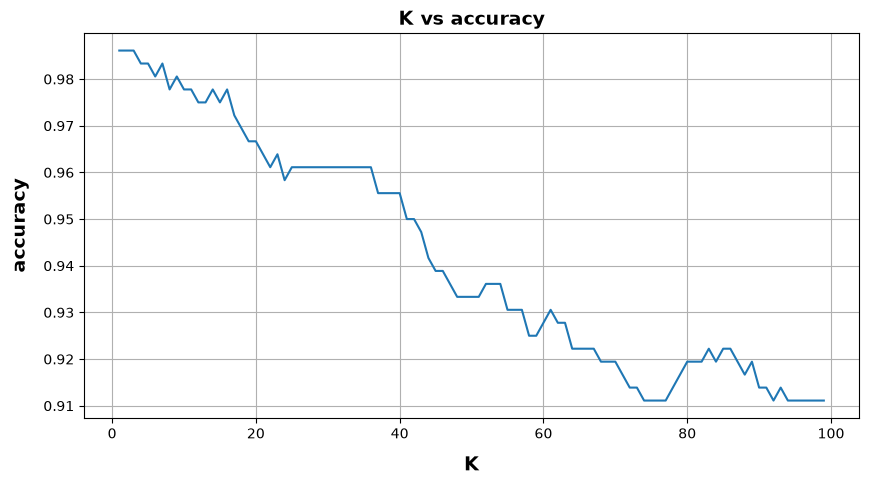

In [127]:
# Plot accuracy against k.
plt.figure(figsize=(10, 5)) 

plt.plot(x,y)
plt.xlabel("K", fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel("accuracy", fontsize=14, fontweight='bold', labelpad=10)
plt.title("K vs accuracy", fontsize=14, fontweight='bold')
plt.grid()
plt.show()

## 10. Results, limitations and next steps

### Results (k = 5, Euclidean distance, raw pixels)

| Metric | Value |
|---|---|
| Test accuracy | 0.983 (354 / 360) |
| Weakest digit (precision / recall) | 8: 0.941 / 0.914 |
| Digits with perfect precision and recall | 0, 2, 3, 5 |
| Best k in the sweep (test set) | 1 to 3 (0.986) |

### Limitations

- **Small test set.** With 360 test images, each extra mistake changes accuracy by about 0.28 percentage points, so small differences between settings are noise.
- **Single split.** All numbers come from one train/test split with `random_state=42`.
- **k sweep on the test set.** It shows the trend but is not a valid way to choose k (see section 9).
- **Prediction cost.** Each prediction computes distances to all 1,437 training images, `O(n · d)` per query, and the per-image Python loop is slow for large datasets.
- **Easy dataset.** These 8×8 images are small and clean. Larger images such as MNIST (28×28) are much harder for plain pixel-distance KNN.

### Possible next steps

- Choose k with **k-fold cross-validation** on the training set.
- Display the **misclassified digits** to see why 8 and 9 are confused.
- Compare **Euclidean, Manhattan and Minkowski** distances, and **distance-weighted voting**.
- Try **PCA** to reduce the 64 dimensions before running KNN.
- Validate against `sklearn.neighbors.KNeighborsClassifier`.